In [53]:
import pandas as pd

In [54]:
df=pd.read_csv("cardekho_dataset.csv")

In [55]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [56]:
df.shape

(15411, 14)

In [57]:
df.describe()

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [58]:
df.isnull().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [59]:
df.duplicated().sum()

np.int64(0)

In [60]:
df.select_dtypes(include="object").nunique()

C:\Users\prath\AppData\Local\Temp\ipykernel_8876\251659734.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").nunique()


car_name             121
brand                 32
model                120
seller_type            3
fuel_type              5
transmission_type      2
dtype: int64

In [61]:
df.columns.tolist()

['Unnamed: 0',
 'car_name',
 'brand',
 'model',
 'vehicle_age',
 'km_driven',
 'seller_type',
 'fuel_type',
 'transmission_type',
 'mileage',
 'engine',
 'max_power',
 'seats',
 'selling_price']

In [62]:
df=df.drop(columns=["car_name","model", "Unnamed: 0"])

In [63]:
print(df["km_driven"].quantile([0.95, 0.99, 0.999]))

0.950    120000.0
0.990    180000.0
0.999    479590.0
Name: km_driven, dtype: float64


In [64]:
limit = df["selling_price"].quantile(0.99)
df=df[df["selling_price"]<=limit].reset_index(drop=True)

In [65]:
df["km_driven"]=df["km_driven"].clip(upper=180000)
print("Max km after clipping : ", df["km_driven"].max())

Max km after clipping :  180000


In [66]:
df=pd.get_dummies(df, drop_first=True, dtype=int)

In [67]:
X=df.drop(columns=["selling_price"])
y=df["selling_price"]

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
x_train, x_test, y_train, y_test=train_test_split(X, y, test_size=0.2, random_state=42)

In [70]:
x_train.shape

(12204, 39)

In [71]:
y_train.shape

(12204,)

In [72]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [73]:
m=LinearRegression()
m.fit(x_train, y_train)
pred=m.predict(x_test)

In [74]:
print("Mean Absolute Error", mean_absolute_error(y_test, pred))
print("Mean Squared Error", mean_squared_error(y_test, pred))
print("r2_score ", r2_score(y_test, pred))

Mean Absolute Error 162236.6444652271
Mean Squared Error 75703063957.47957
r2_score  0.7871846580916458


In [75]:
from sklearn.ensemble import RandomForestRegressor

In [76]:
m2=RandomForestRegressor()
m2.fit(x_train, y_train)
pred2=m2.predict(x_test)

In [77]:
print("MAE", mean_absolute_error(y_test, pred2))
print("MSE", mean_squared_error(y_test, pred2))
print("r2 score", r2_score(y_test, pred2))

MAE 87504.07496344033
MSE 22678895692.495186
r2 score 0.9362454214057553


In [78]:
for name, model in [("LinearRegression",m), ("RandomForestRegressor", m2)]:
    pred=model.predict(x_train)
    r2_train = r2_score( y_train, pred)
    pred2=model.predict(x_test)
    r2_test = r2_score( y_test, pred2)

    print("Model : ", name)
    print("Trian dataset r2_score : ", r2_train)
    print("Test dataset r2_score : ", r2_test)
    print("Performance Gap : ", r2_train - r2_test)
    print()

Model :  LinearRegression
Trian dataset r2_score :  0.7803862509236954
Test dataset r2_score :  0.7871846580916458
Performance Gap :  -0.006798407167950438

Model :  RandomForestRegressor
Trian dataset r2_score :  0.9896238719236736
Test dataset r2_score :  0.9362454214057553
Performance Gap :  0.05337845051791834



In [79]:
import numpy as np

In [80]:
y_train_log = np.log1p(y_train)


In [81]:
ma=LinearRegression()
ma.fit(x_train, y_train_log)
m2a=RandomForestRegressor()
m2a.fit(x_train, y_train_log)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [82]:
for name, model in [("LinearRegression",ma), ("RandomForestRegressor", m2a)]:
    preda=np.expm1(model.predict(x_train))
    pred2a=np.expm1(model.predict(x_test))

    print("Model : ", name)
    print("r2 score train : ", r2_score(y_train, preda))
    print("r2 score test : ", r2_score(y_test, pred2a))
    print("MAE : ", mean_absolute_error(y_test, pred2a))
    print()

Model :  LinearRegression
r2 score train :  0.809496309353473
r2 score test :  0.8310884460573276
MAE :  127011.92325659798

Model :  RandomForestRegressor
r2 score train :  0.9890549182855813
r2 score test :  0.9382540616598177
MAE :  86571.43878490357



In [83]:
from sklearn.model_selection import RandomizedSearchCV

In [84]:
param_grid = {
    "n_estimators" : [100, 200, 300],
    "max_depth" : [10, 20, 30, None],
    "min_samples_leaf" : [1, 2, 3],
    "min_samples_split" : [2, 5, 7],
    "max_features" : ["sqrt", 0.5, 1.0]
}

In [85]:
search=RandomizedSearchCV(
    RandomForestRegressor(),
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1

)

In [86]:
search.fit(x_train, y_train_log)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [10, 20, ...], 'max_features': ['sqrt', 0.5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns th

In [87]:
best=search.best_estimator_
print("best parameters : ", search.best_params_)

best parameters :  {'n_estimators': 200, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30}


In [88]:
pred_tuning = np.expm1(best.predict(x_train))
pred_tuning2=np.expm1(best.predict(x_test))


print("for train dataset : " ,r2_score(y_train, pred_tuning))
print("for test dataset : ", r2_score(y_test, pred_tuning2))
print("MAE : ", mean_absolute_error(y_test, pred_tuning2))

for train dataset :  0.9734445567338559
for test dataset :  0.9394868217540869
MAE :  84631.3679661566


In [89]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score


In [90]:
kf=KFold(n_splits = 5, shuffle = True, random_state=42)

In [91]:
model=[
   ( "LinearRegression" ,LinearRegression()),
   ( "Random Forest" ,RandomForestRegressor(
        n_estimators=200,
        min_samples_split=7,
        min_samples_leaf=1,
        max_depth=30,
        max_features=0.5,
        n_jobs=-1,
        random_state=42

    ))
]

In [92]:
for name, m in model:
    wrapped = TransformedTargetRegressor(
        regressor = m, func=np.log1p, inverse_func= np.expm1
    )

    print("Model  : ", name)
    score= cross_val_score(wrapped, X, y, cv=kf, scoring="r2")
    print(np.round(score,4))
    print("mean : " , score.mean())
    print("std : ", score.std())
    print()


Model  :  LinearRegression
[0.8311 0.7678 0.8387 0.8047 0.7896]
mean :  0.8063744240830856
std :  0.026171051797560668

Model  :  Random Forest
[0.9398 0.9282 0.9379 0.9314 0.937 ]
mean :  0.9348503113479181
std :  0.004364501142402801



In [93]:
r1=RandomForestRegressor(
        n_estimators=200,
        min_samples_split=7,
        min_samples_leaf=1,
        max_depth=30,
        max_features=0.5,
        n_jobs=-1,
        random_state=42

    )

r1.fit(x_train, y_train_log)



,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",30
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",7
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",0.5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max

In [94]:
imp=pd.Series(r1.feature_importances_, index=x_train.columns)
top=imp.sort_values(ascending= False).head(10)

In [95]:
print(top)

max_power                   0.428403
vehicle_age                 0.234554
engine                      0.159315
transmission_type_Manual    0.041715
km_driven                   0.035649
mileage                     0.031025
fuel_type_Diesel            0.020582
fuel_type_Petrol            0.009215
seats                       0.006329
brand_Toyota                0.006168
dtype: float64


In [96]:
import matplotlib.pyplot as plt

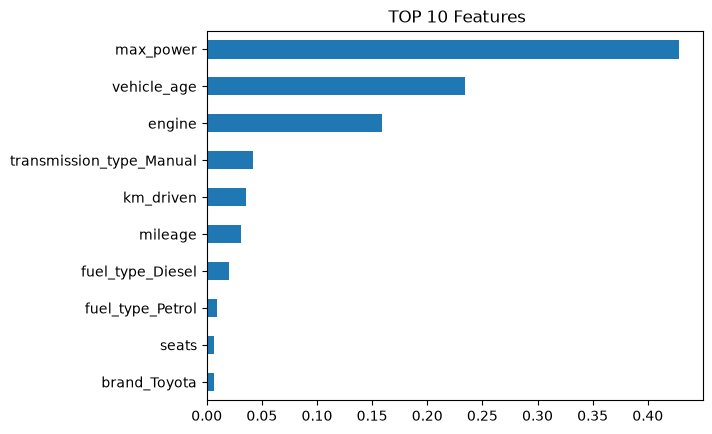

In [97]:
top.sort_values().plot(kind= "barh")
plt.title(" TOP 10 Features")
plt.show()

In [98]:
import joblib

In [99]:
final_model=TransformedTargetRegressor(
    regressor= RandomForestRegressor(
    n_estimators=200,
    min_samples_split=7,
    min_samples_leaf=1,
    max_depth=30,
    max_features=0.5,
    n_jobs=-1,
    random_state=42
    ),
    func=np.log1p,
    inverse_func= np.expm1
    
)

final_model.fit(x_train, y_train)

print(final_model.score(x_test, y_test))



0.9394850922095598


In [100]:
joblib.dump(final_model, "car_price_model.pkl")
joblib.dump(list(x_train.columns), "columns.pkl")

['columns.pkl']

In [101]:
columns = joblib.load("columns.pkl")
print(list(columns))

['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'brand_BMW', 'brand_Datsun', 'brand_Force', 'brand_Ford', 'brand_Honda', 'brand_Hyundai', 'brand_ISUZU', 'brand_Isuzu', 'brand_Jaguar', 'brand_Jeep', 'brand_Kia', 'brand_Land Rover', 'brand_Lexus', 'brand_MG', 'brand_Mahindra', 'brand_Maruti', 'brand_Mercedes-Benz', 'brand_Mini', 'brand_Nissan', 'brand_Porsche', 'brand_Renault', 'brand_Skoda', 'brand_Tata', 'brand_Toyota', 'brand_Volkswagen', 'brand_Volvo', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG', 'fuel_type_Petrol', 'transmission_type_Manual']


In [102]:
raw = pd.read_csv("cardekho_dataset.csv")

In [103]:
all_brands=sorted(raw["brand"].unique())
missing = [b for b in all_brands if f"brand_{b}" not in columns]
print(missing)

['Audi', 'Bentley', 'Ferrari', 'Maserati', 'Mercedes-AMG', 'Rolls-Royce']
